# Why does tracking shuffled objects reverse fully ablated CR?

Fresh, cache-only investigation; no previous investigation notebook consulted. **Average token log likelihood only** throughout. Load the 300 local BBM tracking traces, not the full 8,584-example suite. Scores refer to existing teacher-forced runs, not newly generated solutions.

Questions: Which scores detect the annotated first error? Does the reversal survive excluding unverified post-error steps and controlling for position? Which likelihood component causes it? What do actual traces and annotations look like?

Notation: F = mean LL with question + history; G = generic prompt, no history; Q = generic prompt + history (question ablated); H = question, no history. Fully ablated CR = F−G; question CR = F−Q; history CR = F−H. All plotted detection scores point **toward error** as explicitly named. Positive CR is included as an exploratory reversal, not an a-priori validated detector.

## Executive summary

**The reversal is mainly a step-role confound, not an inverted notion of correctness.** Repetitive intermediate state lists obtain a large likelihood boost from *history alone*, whether their permutation is right or wrong. Fully ablated CR mixes this boost with question support; opening and concluding steps have different baselines. Comparing verified intermediate steps removes the consistent reversal.

**Negative question-ablated CR works best for pooled detection (AUROC 0.84–0.90) and raw within-trace localization (56–71% on known-error traces).** Full-context perplexity is excellent at matched positions, but a poor unconstrained trace-local score. The notebook includes eight score variants, five models, position-controlled comparisons, bootstrap intervals, small cross-task comparisons, independently simulated example swaps, and annotation/failure audits. See the final conclusions for interpretation and limitations.

In [7]:
from pathlib import Path
import json, sys, logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.metrics import roc_auc_score

ROOT = Path.cwd() if (Path.cwd() / 'experiment_setup').exists() else Path.cwd() / 'final'
sys.path.insert(0, str(ROOT))
from experiment_setup import dc_pmi
from experiment_setup.benchmarks import Example, BBM_TASKS, sample_control_and_error
logging.getLogger('experiment_setup').setLevel(logging.WARNING)
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 20)
MODELS = {
    'Qwen3.5-4B': ('Qwen/Qwen3.5-4B', 'qwen35_4b'),
    'Qwen3.5-9B': ('Qwen/Qwen3.5-9B', 'qwen35_9b'),
    'Qwen3.5-27B': ('Qwen/Qwen3.5-27B', 'qwen35_27b'),
    'Llama3.1-8B': ('meta-llama/Llama-3.1-8B-Instruct', 'llama31_8b'),
    'Llama3.2-3B': ('meta-llama/Llama-3.2-3B-Instruct', 'llama32_3b'),
}

def local_task(task):
    with (ROOT / 'BIG-Bench-Mistake' / f'{task}.jsonl').open() as f:
        rows = [json.loads(line) for line in f]
    return [Example('BIG-Bench-Mistake', task, str(i), r['input'], tuple(r['steps']),
                    r['mistake_index'], r['target']) for i, r in enumerate(rows)], rows

examples, raw = local_task('tracking_shuffled_objects')
lookup = {e.uid: e for e in examples}
meta = pd.DataFrame([dict(uid=e.uid, n_steps=len(e.steps), label=e.label,
    answer_correct=r['answer'] == r['target']) for e, r in zip(examples, raw)])
display(pd.crosstab(meta.label.notna().rename('annotated error'), meta.answer_correct))
print(f'{len(examples)} traces; {meta.label.notna().sum()} annotated first errors')
frames = []
for model, (model_id, stem) in MODELS.items():
    frame = dc_pmi.load_run(examples, model_id=model_id, average_ll=True,
                            cache_path=ROOT / 'cache' / f'dc_pmi_{stem}_arm.sqlite')
    assert frame.uid.nunique() == len(examples)
    frames.append(frame.assign(model=model))
scores = pd.concat(frames, ignore_index=True).merge(meta[['uid', 'n_steps']], on='uid')
scores['F'] = scores.average_log_likelihood
scores['G'] = scores.F - scores.dc_pmi_generic_domain
scores['Q'] = scores.F - scores.dc_pmi_question_ablation
scores['H'] = scores.F - scores.dc_pmi_history_ablation
# Positional roles, not a semantic parser: a few opening steps already perform a swap.
scores['role'] = np.select([scores.step.eq(0), scores.step.eq(scores.n_steps - 1)],
                            ['opening', 'final'], default='intermediate')
scores['status'] = np.select([scores.first_error, ~scores.verified],
                             ['first error', 'post-error (unknown)'], default='annotated correct')
assert np.isfinite(scores[['F','G','Q','H']]).all().all()
print(f'{len(scores):,} model-step rows loaded; no total-LL scores used.')

answer_correct,False,True
annotated error,,
False,8,32
True,249,11


300 traces; 260 annotated first errors
8,085 model-step rows loaded; no total-LL scores used.


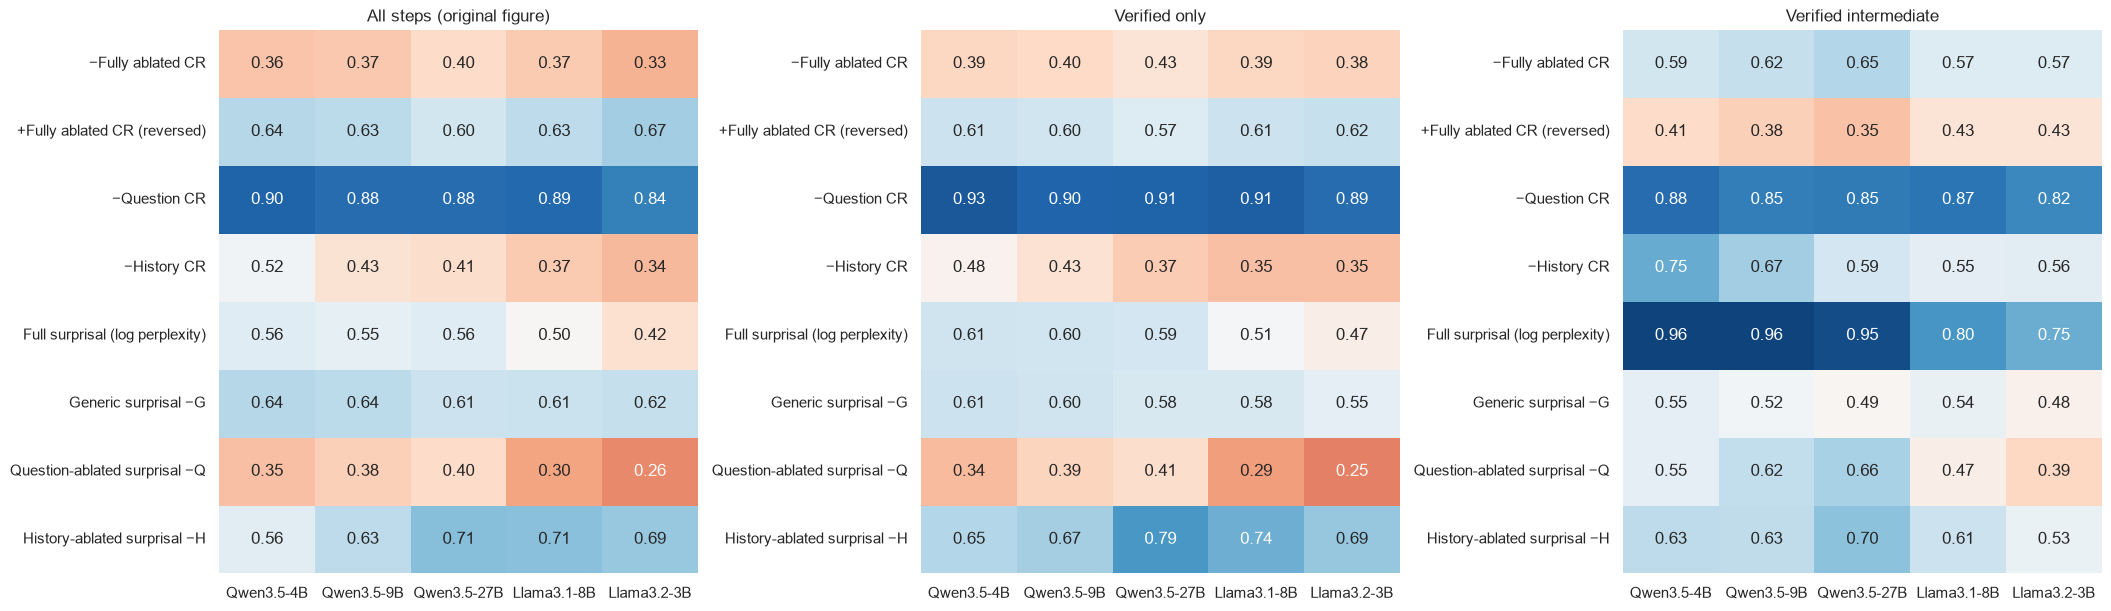

status,annotated correct,first error,post-error (unknown)
role,,,
final,40,3,257
intermediate,551,257,209
opening,300,0,0


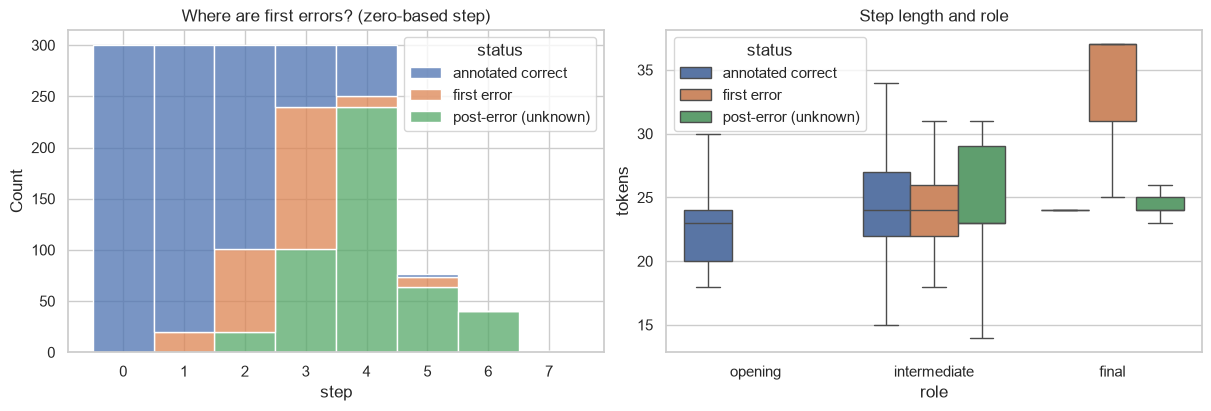

In [8]:
METHODS = {
    '−Fully ablated CR': -scores.dc_pmi_generic_domain,
    '+Fully ablated CR (reversed)': scores.dc_pmi_generic_domain,
    '−Question CR': -scores.dc_pmi_question_ablation,
    '−History CR': -scores.dc_pmi_history_ablation,
    'Full surprisal (log perplexity)': -scores.F,
    'Generic surprisal −G': -scores.G,
    'Question-ablated surprisal −Q': -scores.Q,
    'History-ablated surprisal −H': -scores.H,
}
for method, values in METHODS.items():
    scores[method] = values

def auc(frame, method):
    return roc_auc_score(frame.first_error, frame[method]) if frame.first_error.nunique() == 2 else np.nan

rows = []
for model, group in scores.groupby('model', sort=False):
    for population, subset in [('All steps (original figure)', group),
                               ('Verified only', group[group.verified]),
                               ('Verified intermediate', group[group.verified & group.role.eq('intermediate')])]:
        for method in METHODS:
            rows.append(dict(model=model, population=population, method=method, auc=auc(subset, method)))
results = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 3, figsize=(21, 6), layout='constrained')
for ax, (population, group) in zip(axes, results.groupby('population', sort=False)):
    table = group.pivot(index='method', columns='model', values='auc').reindex(index=METHODS, columns=MODELS)
    sns.heatmap(table, ax=ax, annot=True, fmt='.2f', vmin=0, vmax=1, center=.5, cmap='RdBu', cbar=False)
    ax.set(title=population, xlabel='', ylabel='')
plt.show()

# Structural baseline: labels/positions, with no likelihood information.
one = scores[scores.model.eq('Qwen3.5-4B')]
display(one.groupby(['role', 'status'], observed=True).size().unstack(fill_value=0))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
sns.histplot(data=one, x='step', hue='status', multiple='stack', discrete=True, ax=axes[0])
sns.boxplot(data=one, x='role', y='tokens', hue='status', ax=axes[1], showfliers=False)
axes[0].set_title('Where are first errors? (zero-based step)')
axes[1].set_title('Step length and role')
plt.show()

## Four scoring methods by model

First-error AUROC on **all steps** of the 300 tracking-shuffled-objects traces, matching the original task-level evaluation. Only the annotated first-error step is positive; post-error steps count as negatives, not verified-correct steps. All likelihoods use average LL. Higher perplexity and lower CR indicate errors; the dashed line marks chance AUROC.

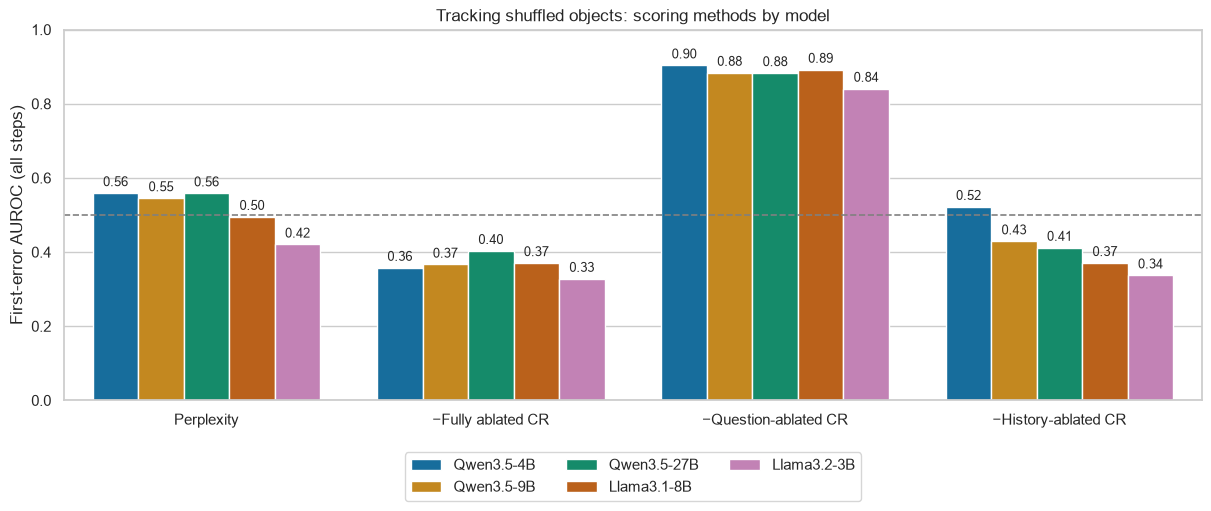

In [9]:
bar_methods = {
    'perplexity': 'Perplexity',
    'dc_pmi_generic_domain': '−Fully ablated CR',
    'dc_pmi_question_ablation': '−Question-ablated CR',
    'dc_pmi_history_ablation': '−History-ablated CR',
}
bar_rows = []
for model in MODELS:
    group = scores.loc[scores.model.eq(model)]
    for metric, label in bar_methods.items():
        evidence = dc_pmi.error_evidence_score(group, metric)
        bar_rows.append(dict(model=model, method=label,
                             auroc=roc_auc_score(group.first_error, evidence)))
bar_results = pd.DataFrame(bar_rows)
fig, ax = plt.subplots(figsize=(12, 5), layout='constrained')
sns.barplot(data=bar_results, x='method', y='auroc', hue='model',
            order=list(bar_methods.values()), hue_order=list(MODELS),
            palette='colorblind', errorbar=None, ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3, fontsize=9)
ax.axhline(0.5, color='gray', linestyle='--', linewidth=1.2)
ax.set(title='Tracking shuffled objects: scoring methods by model',
       xlabel='', ylabel='First-error AUROC (all steps)', ylim=(0, 1))
ax.legend(title='', loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=3)
plt.show()

## Full trace accuracy: CV-thresholded question CR versus LLM judge

**Full accuracy** means predicting the exact first-error step, or NONE for an error-free trace, across all 300 traces. For CR, choose the lowest question-ablated CR step (earliest on ties); predict it only if its negative CR meets the threshold, otherwise NONE. Invalid judge responses count as wrong.

Unlike the optimistic `cv='prefit'` evaluation in `comparison.ipynb`, this chart uses **five-fold stratified out-of-fold evaluation**. Within each training fold, `TunedThresholdClassifierCV(cv='prefit')` selects the threshold maximizing exact-location-or-NONE accuracy over distinct training evidence values and all/none endpoints. That threshold is evaluated only on the held-out fold. Each trace contributes one held-out prediction; folds are identical across models. Thresholds are task- and model-specific. This is not binary error-presence accuracy.

Reuse the loaded average-LL tracking scores. As in `comparison.ipynb`, Qwen judge results come from full-run CSVs and Llama results from the cache, restricted to these same traces. No model inference or additional likelihood loading. The method choice itself remains exploratory, not independently validated by this threshold CV.

method,LLM judge,−Question CR (5-fold CV)
model,,
Qwen3.5-4B,33.3,64.0
Qwen3.5-9B,34.7,61.0
Qwen3.5-27B,50.0,58.0
Llama3.1-8B,45.7,65.0
Llama3.2-3B,26.3,50.0


,model,fold,threshold,n_train,n_test
0,Qwen3.5-4B,1,-0.122526,240,60
1,Qwen3.5-4B,2,-0.117213,240,60
2,Qwen3.5-4B,3,-0.122526,240,60
3,Qwen3.5-4B,4,-0.122526,240,60
4,Qwen3.5-4B,5,-0.122526,240,60
5,Qwen3.5-9B,1,-0.090926,240,60
6,Qwen3.5-9B,2,-0.090926,240,60
7,Qwen3.5-9B,3,-0.086904,240,60
8,Qwen3.5-9B,4,-0.090926,240,60
9,Qwen3.5-9B,5,-0.073413,240,60


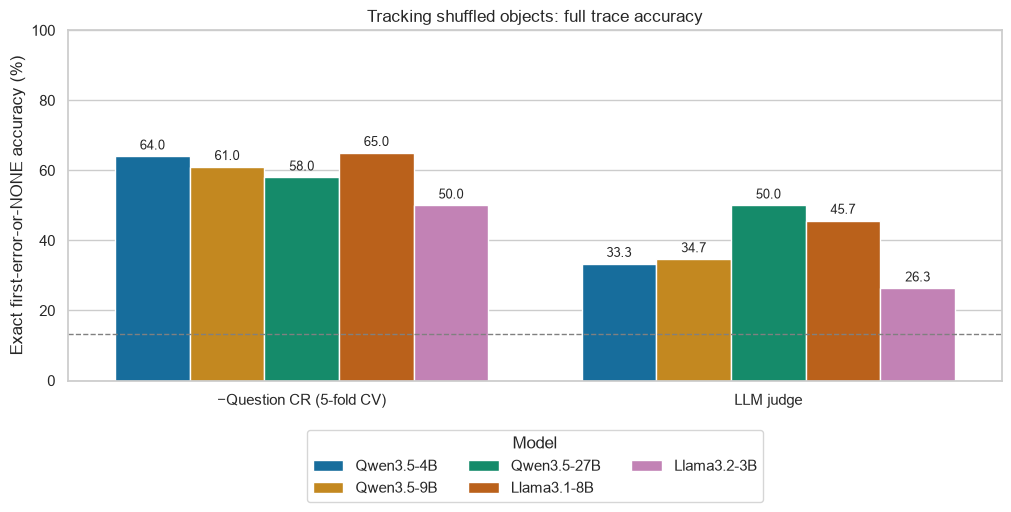

Dashed line: always predict NONE. CR bars are held-out fold predictions; judge bars use the same 300 traces.


In [10]:
from sklearn.metrics import make_scorer
from sklearn.model_selection import StratifiedKFold, TunedThresholdClassifierCV
from experiment_setup import llm_critic


def tracking_exact_accuracy(y_true, y_pred, *, candidate_correct):
    predicted_error = np.asarray(y_pred, dtype=bool)
    actual_error = np.asarray(y_true, dtype=bool)
    return np.mean((~predicted_error & ~actual_error) |
                   (predicted_error & np.asarray(candidate_correct, dtype=bool)))


def tracking_train_threshold(train):
    evidence = train.evidence.to_numpy()
    truth = train.label.notna().to_numpy()
    X = evidence.reshape(-1, 1)
    thresholds = np.unique(np.r_[np.nextafter(evidence.min(), -np.inf),
                                 evidence, np.nextafter(evidence.max(), np.inf)])
    estimator = dc_pmi.RawScoreClassifier().fit(X, truth)
    tuned = TunedThresholdClassifierCV(
        estimator, cv='prefit', refit=False, response_method='decision_function',
        scoring=make_scorer(tracking_exact_accuracy,
                           candidate_correct=train.candidate_correct.to_numpy()),
        thresholds=thresholds,
    ).fit(X, truth)
    return tuned.best_threshold_


def tracking_load_judge(model_id, stem):
    keys = ['benchmark', 'task', 'uid']
    if stem.startswith('qwen35_'):
        frame = pd.read_csv(ROOT / 'runs' / f'llm_judge_{stem}_full_arm.csv',
                            dtype={'uid': str},
                            usecols=[*keys, 'label', 'prediction', 'parse_error'])
    else:
        frame = llm_critic.load_run(examples, model_id=model_id,
                    cache_path=ROOT / 'cache' / f'llm_judge_{stem}_arm.sqlite')
    frame = frame.loc[frame.benchmark.eq('BIG-Bench-Mistake') &
                      frame.task.eq('tracking_shuffled_objects')].copy()
    frame['uid'] = frame.uid.astype(str)
    return frame


tracking_keys = ['benchmark', 'task', 'uid']
tracking_expected = pd.DataFrame([
    dict(benchmark=e.benchmark, task=e.task, uid=str(e.uid), expected_label=e.label)
    for e in examples
])
assert len(tracking_expected) == 300 and not tracking_expected.duplicated(tracking_keys).any()
tracking_folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(
    tracking_expected, tracking_expected.expected_label.notna()))
tracking_accuracy_rows, tracking_threshold_rows, tracking_prediction_rows = [], [], []
for model, (model_id, stem) in MODELS.items():
    group = scores.loc[scores.model.eq(model)].sort_values('step').copy()
    group['evidence'] = -group.dc_pmi_question_ablation
    candidates = group.loc[group.groupby(tracking_keys, sort=False).evidence.idxmax()]
    candidates = tracking_expected.merge(candidates, on=tracking_keys, how='left',
                                          validate='one_to_one', indicator=True)
    assert candidates['_merge'].eq('both').all()
    assert candidates.label.fillna(-1).eq(candidates.expected_label.fillna(-1)).all()
    candidates['candidate_correct'] = candidates.step.eq(candidates.label)
    out_of_fold = np.full(len(candidates), np.nan)
    for fold, (train_idx, test_idx) in enumerate(tracking_folds, 1):
        threshold = tracking_train_threshold(candidates.iloc[train_idx])
        test = candidates.iloc[test_idx]
        out_of_fold[test_idx] = np.where(test.evidence.ge(threshold), test.step, -1)
        tracking_threshold_rows.append(dict(model=model, fold=fold, threshold=threshold,
                                             n_train=len(train_idx), n_test=len(test_idx)))
    assert np.isfinite(out_of_fold).all()
    truth = candidates.expected_label.fillna(-1).to_numpy()
    tracking_accuracy_rows.append(dict(model=model, method='−Question CR (5-fold CV)',
                                        accuracy=(out_of_fold == truth).mean(), n=len(truth)))

    judge = tracking_expected.merge(tracking_load_judge(model_id, stem),
                                     on=tracking_keys, how='left',
                                     validate='one_to_one', indicator=True)
    assert judge['_merge'].eq('both').all(), 'Missing judge predictions'
    assert judge.label.fillna(-1).eq(judge.expected_label.fillna(-1)).all()
    judge_correct = judge.parse_error.isna() & judge.prediction.fillna(-1).eq(
        judge.expected_label.fillna(-1))
    tracking_accuracy_rows.append(dict(model=model, method='LLM judge',
                                        accuracy=judge_correct.mean(), n=len(judge)))
    tracking_prediction_rows.append(pd.DataFrame(dict(
        model=model, uid=candidates.uid, label=truth, cr_prediction=out_of_fold,
        cr_correct=out_of_fold == truth, judge_correct=judge_correct.to_numpy())))

tracking_accuracy = pd.DataFrame(tracking_accuracy_rows)
tracking_thresholds = pd.DataFrame(tracking_threshold_rows)
tracking_predictions = pd.concat(tracking_prediction_rows, ignore_index=True)
display(tracking_accuracy.pivot(index='model', columns='method', values='accuracy')
        .reindex(list(MODELS)).mul(100).round(1))
display(tracking_thresholds)
fig, ax = plt.subplots(figsize=(10, 5), layout='constrained')
sns.barplot(data=tracking_accuracy.assign(percent=lambda d: 100 * d.accuracy),
            x='method', y='percent', hue='model',
            order=['−Question CR (5-fold CV)', 'LLM judge'], hue_order=list(MODELS),
            palette='colorblind', errorbar=None, ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=3, fontsize=9)
ax.axhline(100 * tracking_expected.expected_label.isna().mean(), color='gray',
           linestyle='--', linewidth=1)
ax.set(title='Tracking shuffled objects: full trace accuracy', xlabel='',
       ylabel='Exact first-error-or-NONE accuracy (%)', ylim=(0, 100))
ax.legend(title='Model', loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=3)
plt.show()
print('Dashed line: always predict NONE. CR bars are held-out fold predictions; judge bars use the same 300 traces.')

## Follow-up 1: separate step structure from correctness

The reversal disappears when restricting to verified intermediate steps. There are **no annotated errors at the opening step**, and only three at the final step. Thus a pooled AUROC compares unlike text roles. Also, 466/1,617 steps are *after* the first error; treating them as negative does not make them correct.

Below we inspect the four mean-LL components and the exact decomposition

**fully ablated CR = question CR + history gain under a generic question = (F−Q) + (Q−G).**

The latter term can reward learning the names, object vocabulary and repetitive state-list format from earlier steps, even if the current permutation is wrong. This is a mechanistic hypothesis about what the context supplies, not a token-level causal attribution.

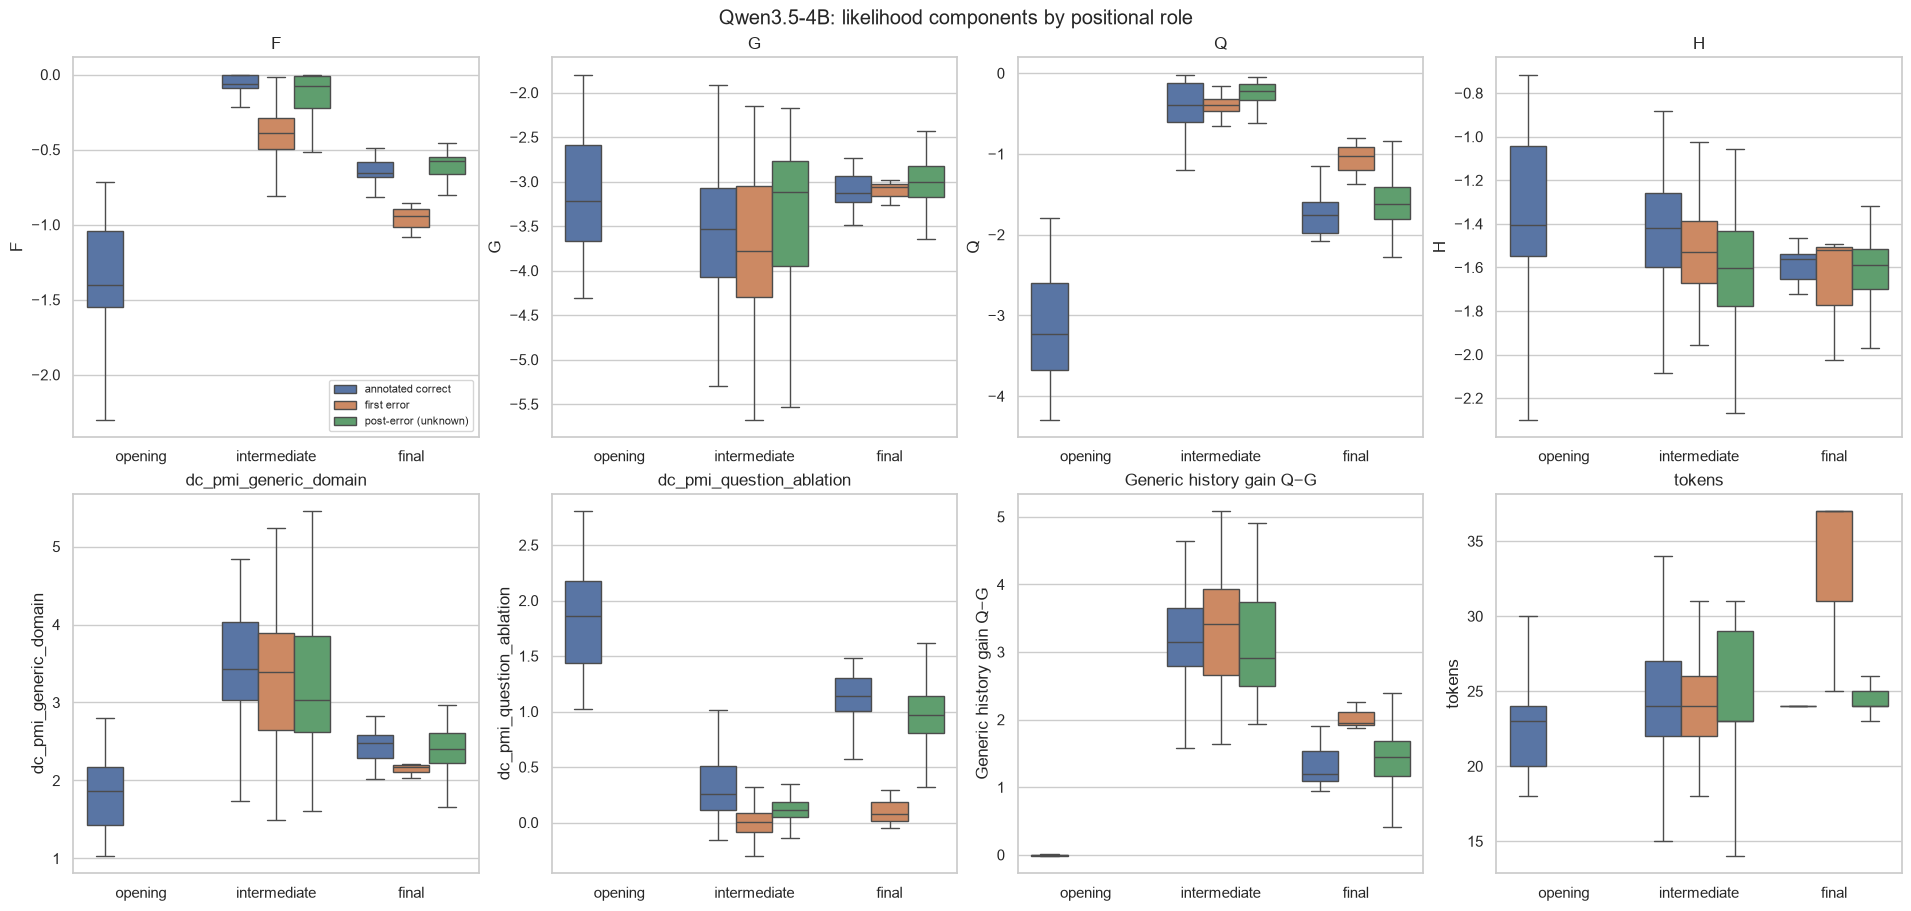

F      G      Q  dc_pmi_generic_domain  \
role         status                                                             
final        annotated correct    -0.671 -3.093 -1.729                  2.423   
             first error          -0.961 -3.102 -1.068                  2.141   
             post-error (unknown) -0.695 -3.030 -1.610                  2.335   
intermediate annotated correct    -0.070 -3.573 -0.389                  3.503   
             first error          -0.410 -3.686 -0.420                  3.275   
             post-error (unknown) -0.149 -3.317 -0.260                  3.168   
opening      annotated correct    -1.314 -3.126 -3.131                  1.812   

                                   dc_pmi_question_ablation  \
role         status                                           
final        annotated correct                        1.058   
             first error                              0.107   
             post-error (unknown)                     0.915   
intermediate annotated correct                        0.319   
             first error                              0.009   
             post-error (unknown)                     0.110   
opening      annotated correct                        1.818   

                                   Generic history gain Q−G  
role         status                                          
final        annotated correct                        1.364  
             first error                              2.034  
             post-error (unknown)                     1.420  
intermediate annotated correct                        3.184  
             first error                              3.266  
             post-error (unknown)                     3.058  
opening      annotated correct                       -0.005

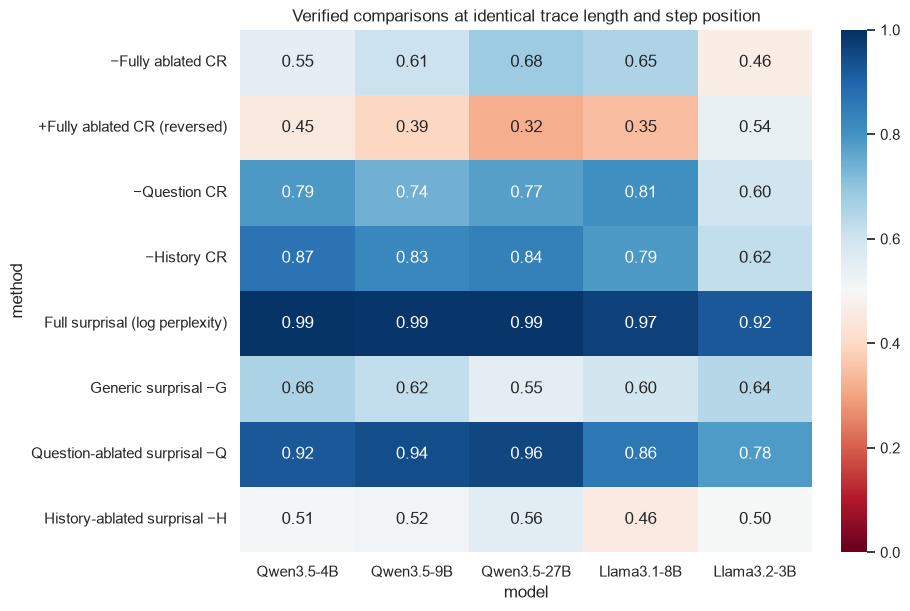

40 distinct matched pairs; 40/260 error traces retained (limited controls).


model,Qwen3.5-4B,Qwen3.5-9B,Qwen3.5-27B,Llama3.1-8B,Llama3.2-3B
method,,,,,
−Fully ablated CR,0.475,0.625,0.600,0.675,0.400
+Fully ablated CR (reversed),0.525,0.375,0.400,0.325,0.600
−Question CR,0.750,0.750,0.725,0.750,0.600
−History CR,0.900,0.850,0.875,0.850,0.700
Full surprisal (log perplexity),1.000,0.975,0.975,0.950,0.875
Generic surprisal −G,0.700,0.725,0.625,0.625,0.750
Question-ablated surprisal −Q,0.900,0.850,0.850,0.850,0.750
History-ablated surprisal −H,0.375,0.375,0.450,0.325,0.375


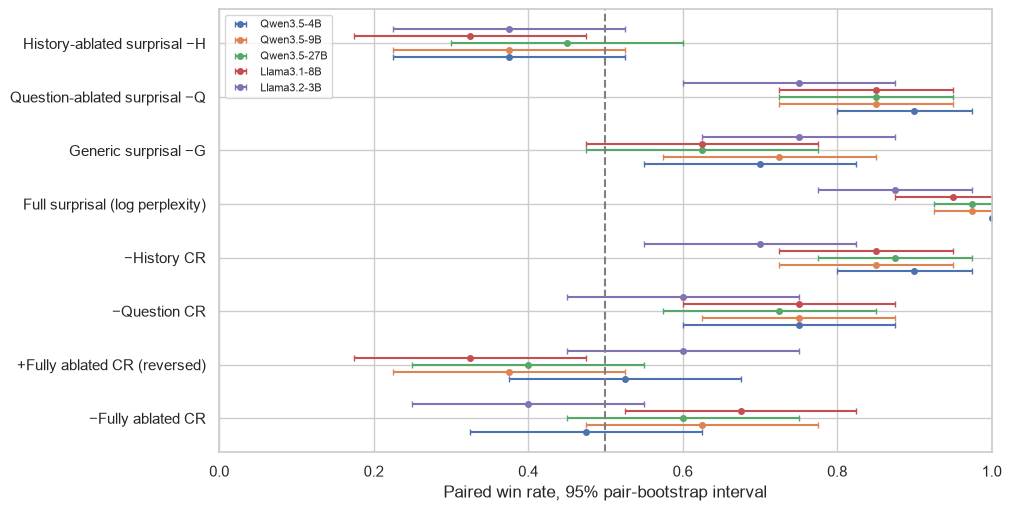

In [11]:
scores['Generic history gain Q−G'] = scores.Q - scores.G
assert np.allclose(scores.dc_pmi_generic_domain,
                   scores.dc_pmi_question_ablation + scores['Generic history gain Q−G'])
one = scores[scores.model.eq('Qwen3.5-4B')].copy()
fig, axes = plt.subplots(2, 4, figsize=(19, 9), layout='constrained')
for ax, column in zip(axes.flat, ['F','G','Q','H','dc_pmi_generic_domain',
                                'dc_pmi_question_ablation','Generic history gain Q−G','tokens']):
    sns.boxplot(data=one, x='role', y=column, hue='status',
                order=['opening','intermediate','final'], showfliers=False, ax=ax)
    ax.set(xlabel='', title=column)
    if ax != axes[0,0]:
        ax.get_legend().remove()
axes[0,0].legend(fontsize=8)
fig.suptitle('Qwen3.5-4B: likelihood components by positional role')
plt.show()
display(one.groupby(['role','status'], observed=True)[
    ['F','G','Q','dc_pmi_generic_domain','dc_pmi_question_ablation','Generic history gain Q−G']].mean().round(3))

# Each cell compares errors only to verified correct steps of the SAME position and length.
# Weight each valid stratum by its number of positive/negative pairs (conditional AUROC).
def conditional_auc(frame, method):
    values, weights = [], []
    for _, g in frame[frame.verified].groupby(['n_steps','step']):
        if g.first_error.nunique() == 2:
            values.append(auc(g, method))
            weights.append(int(g.first_error.sum()) * int((~g.first_error).sum()))
    return np.average(values, weights=weights) if weights else np.nan

conditional = pd.DataFrame([{ 'model': m, 'method': method,
    'AUROC within (length, position)': conditional_auc(g, method)}
    for m, g in scores.groupby('model', sort=False) for method in METHODS])
fig, ax = plt.subplots(figsize=(9,6), layout='constrained')
sns.heatmap(conditional.pivot(index='method', columns='model', values='AUROC within (length, position)')
    .reindex(index=METHODS, columns=MODELS), annot=True, fmt='.2f', center=.5, vmin=0, vmax=1,
    cmap='RdBu', ax=ax)
ax.set_title('Verified comparisons at identical trace length and step position')
plt.show()

# Matched error-free controls give an independent, smaller position-controlled view.
errors, controls = sample_control_and_error(examples, seed=42)
pairs = pd.DataFrame([dict(pair=i, error_uid=e.uid, control_uid=c.uid, step=e.label)
                      for i, (e,c) in enumerate(zip(errors,controls))])
print(f'{len(pairs)} distinct matched pairs; {len(errors)}/260 error traces retained (limited controls).')
matched_rows = []
for model, g in scores.groupby('model', sort=False):
    left = pairs.merge(g, left_on=['error_uid','step'], right_on=['uid','step'])
    right = pairs.merge(g, left_on=['control_uid','step'], right_on=['uid','step'])
    assert left.pair.tolist() == right.pair.tolist()
    for method in METHODS:
        wins = (left[method].to_numpy() > right[method].to_numpy()).astype(float)
        wins += .5 * (left[method].to_numpy() == right[method].to_numpy())
        rng = np.random.default_rng(42)
        boot = rng.choice(wins, size=(2000,len(wins)), replace=True).mean(axis=1)
        lo, hi = np.quantile(boot, [.025,.975])
        matched_rows.append(dict(model=model, method=method, paired_win_rate=wins.mean(), lo=lo, hi=hi))
matched = pd.DataFrame(matched_rows)
display(matched.pivot(index='method', columns='model', values='paired_win_rate').reindex(index=METHODS, columns=MODELS).round(3))
fig, ax = plt.subplots(figsize=(10,5), layout='constrained')
for j, model in enumerate(MODELS):
    g = matched[matched.model.eq(model)].set_index('method').reindex(METHODS)
    y = np.arange(len(g)) + (j-2)*.13
    ax.errorbar(g.paired_win_rate, y, xerr=[g.paired_win_rate-g.lo,g.hi-g.paired_win_rate],
                fmt='o', ms=4, label=model, capsize=2)
ax.set(yticks=np.arange(len(METHODS)), yticklabels=list(METHODS), xlabel='Paired win rate, 95% pair-bootstrap interval', xlim=(0,1))
ax.axvline(.5, color='gray', ls='--'); ax.legend(fontsize=8)
plt.show()

## Follow-up 2: is the history-gain term unusual across tasks?

Use one scorer (Qwen3.5-4B) and a fixed random sample of at most 100 traces per other BBM task; no full benchmark loading. Tracking uses all 300 already-loaded traces. These are descriptive comparisons, not equal-precision task rankings. Exclude the known dyck trace 52 as in the source notebook. Compare error-minus-correct mean differences on **verified** steps; means decompose exactly, AUROCs do not.

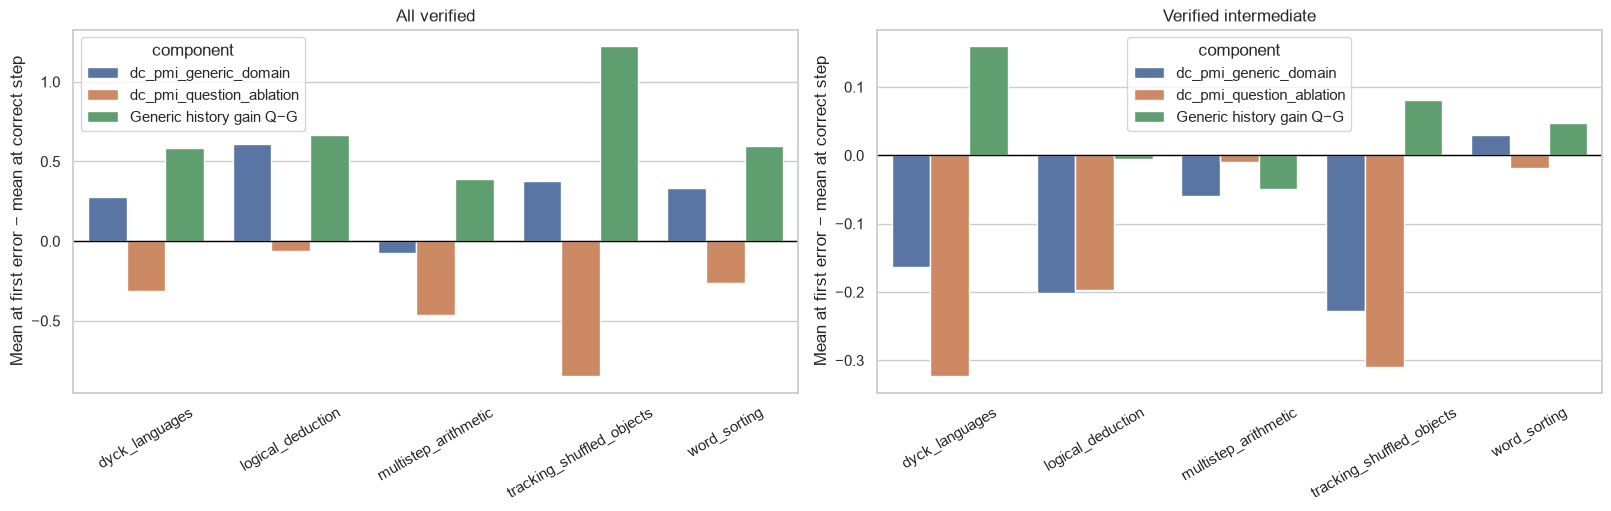

component                                        Generic history gain Q−G  \
task                      population                                        
dyck_languages            All verified                              0.449   
                          Verified intermediate                     0.499   
logical_deduction         All verified                              0.266   
                          Verified intermediate                     0.500   
multistep_arithmetic      All verified                              0.365   
                          Verified intermediate                     0.504   
tracking_shuffled_objects All verified                              0.290   
                          Verified intermediate                     0.462   
word_sorting              All verified                              0.369   
                          Verified intermediate                     0.483   

component                                        dc_pmi_generic_domain  \
task                      population                                     
dyck_languages            All verified                           0.566   
                          Verified intermediate                  0.630   
logical_deduction         All verified                           0.281   
                          Verified intermediate                  0.529   
multistep_arithmetic      All verified                           0.554   
                          Verified intermediate                  0.514   
tracking_shuffled_objects All verified                           0.392   
                          Verified intermediate                  0.594   
word_sorting              All verified                           0.377   
                          Verified intermediate                  0.494   

component                                        dc_pmi_question_ablation  
task                      population                                       
dyck_languages            All verified                              0.754  
                          Verified intermediate                     0.762  
logical_deduction         All verified                              0.517  
                          Verified intermediate                     0.660  
multistep_arithmetic      All verified                              0.703  
                          Verified intermediate                     0.552  
tracking_shuffled_objects All verified                              0.926  
                          Verified intermediate                     0.883  
word_sorting              All verified                              0.686  
                          Verified intermediate                     0.593

,traces,steps,errors
task,,,
dyck_languages,100,2616,70
logical_deduction,100,861,96
multistep_arithmetic,100,514,79
tracking_shuffled_objects,300,1617,260
word_sorting,100,1180,86


In [12]:
import random
cross = [one.copy()]
for task in BBM_TASKS:
    if task == 'tracking_shuffled_objects':
        continue
    candidates, _ = local_task(task)
    candidates = [e for e in candidates if not (task == 'dyck_languages' and e.uid == '52')]
    selected = random.Random(42).sample(candidates, min(100,len(candidates)))
    g = dc_pmi.load_run(selected, model_id=MODELS['Qwen3.5-4B'][0], average_ll=True,
                        cache_path=ROOT / 'cache' / 'dc_pmi_qwen35_4b_arm.sqlite')
    lengths = {e.uid: len(e.steps) for e in selected}
    g['n_steps'] = g.uid.map(lengths)
    g['Generic history gain Q−G'] = g.dc_pmi_generic_domain - g.dc_pmi_question_ablation
    cross.append(g)
cross = pd.concat(cross, ignore_index=True)
cross_rows = []
for task, g in cross.groupby('task'):
    for population, sub in [('All verified', g[g.verified]),
                            ('Verified intermediate', g[g.verified & g.step.gt(0) & g.step.lt(g.n_steps-1)])]:
        for component in ['dc_pmi_generic_domain','dc_pmi_question_ablation','Generic history gain Q−G']:
            cross_rows.append(dict(task=task, population=population, component=component,
                gap=sub.loc[sub.first_error,component].mean()-sub.loc[~sub.first_error,component].mean(),
                negative_auc=roc_auc_score(sub.first_error,-sub[component])))
cross_results = pd.DataFrame(cross_rows)
fig, axes = plt.subplots(1,2, figsize=(16,5), layout='constrained')
for ax, (pop,g) in zip(axes,cross_results.groupby('population',sort=False)):
    sns.barplot(data=g,x='task',y='gap',hue='component',ax=ax)
    ax.axhline(0,color='black',lw=1)
    ax.set(title=pop,ylabel='Mean at first error − mean at correct step',xlabel='')
    ax.tick_params(axis='x',rotation=30)
plt.show()
display(cross_results.pivot(index=['task','population'],columns='component',values='negative_auc').round(3))
display(cross.groupby('task').agg(traces=('uid','nunique'), steps=('step','size'), errors=('first_error','sum')))

## Follow-up 3: read actual runs, not just scores

The first two cases below were chosen by direct inspection, not because their score curves were favorable. UID 0 and UID 50 show the common state-list format and an incorrect final swap. UID 1 is an annotation warning: `mistake_index=None` despite a wrong answer and visibly wrong intermediate state. We keep the original labels in all metrics; **annotated correct** does not guarantee logically correct.

The tiny reference simulator below is deliberately limited to these three manually transcribed initial states. It executes the swaps extracted from the *question*, independently of the model's proposed states. It is not a general relabeling pipeline. Steps in the generated trace need not align one-to-one with swaps.

### UID 0: annotated first error = 3 (zero-based)

Alice, Bob, and Claire are friends and avid readers who occasionally trade books. At the start of the semester, they each buy one new book: Alice gets The Great Gatsby, Bob gets Ulysses, and Claire gets Moby Dick.
As the semester proceeds, they start trading around the new books. First, Alice and Claire swap books. Then, Bob and Claire swap books. Finally, Alice and Claire swap books. At the end of the semester, Alice has
Options:
(A) The Great Gatsby.
(B) Ulysses.
(C) Moby Dick.

Recorded answer: (A); target: (B)

0: At the start: Alice: Gatsby, Bob: Ulysses, Claire: Moby Dick.

1: Alice and Claire swap: Alice: Moby Dick, Bob: Ulysses, Claire: Gatsby.

2: Bob and Claire swap: Alice: Moby Dick, Bob: Gatsby, Claire: Ulysses.

3 <-- annotated first error: Alice and Claire swap: Alice: Gatsby, Bob: Ulysses, Claire: Moby Dick.

4: At the end of the semester, Alice has The Great Gatsby. So the answer is (A)


,operation,Alice,Bob,Claire
0,initial,Gatsby,Ulysses,Moby Dick
1,Alice ↔ Claire,Moby Dick,Ulysses,Gatsby
2,Bob ↔ Claire,Moby Dick,Gatsby,Ulysses
3,Alice ↔ Claire,Ulysses,Gatsby,Moby Dick


,step,status,F,G,Q,dc_pmi_generic_domain,dc_pmi_question_ablation
0,0,annotated correct,-1.222,-2.607,-2.607,1.385,1.385
1,1,annotated correct,-0.071,-3.034,-0.405,2.963,0.334
2,2,annotated correct,-0.001,-2.791,-0.031,2.791,0.030
3,3,first error,-0.355,-3.005,-0.294,2.650,-0.061
4,4,post-error (unknown),-0.626,-2.788,-1.823,2.162,1.197


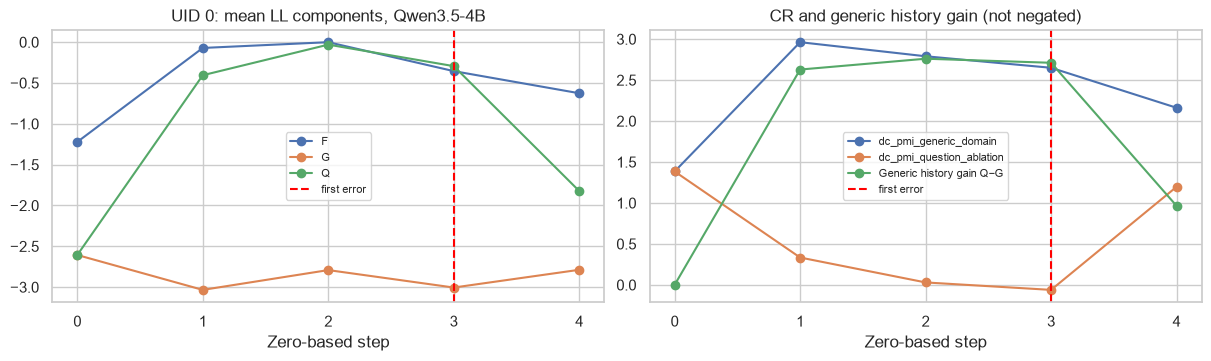

### UID 50: annotated first error = 3 (zero-based)

Alice, Bob, and Claire are dancers at a square dance. At the start of a song, they each have a partner: Alice is dancing with Sam, Bob is dancing with Jamie, and Claire is dancing with Melissa.
Throughout the song, the dancers often trade partners. First, Alice and Bob switch partners. Then, Bob and Claire switch partners. Finally, Alice and Claire switch partners. At the end of the dance, Alice is dancing with
Options:
(A) Sam.
(B) Jamie.
(C) Melissa.

Recorded answer: (C); target: (A)

0: At the start: Alice: Sam, Bob: Jamie, Claire: Melissa.

1: Alice and Bob switch partners: Alice: Jamie, Bob: Sam, Claire: Melissa.

2: Bob and Claire switch partners: Alice: Jamie, Bob: Melissa, Claire: Sam.

3 <-- annotated first error: Alice and Claire switch partners: Alice: Melissa, Bob: Jamie, Claire: Sam.

4: At the end of the dance, Alice is dancing with Melissa. So the answer is (C)


,operation,Alice,Bob,Claire
0,initial,Sam,Jamie,Melissa
1,Alice ↔ Bob,Jamie,Sam,Melissa
2,Bob ↔ Claire,Jamie,Melissa,Sam
3,Alice ↔ Claire,Sam,Melissa,Jamie


,step,status,F,G,Q,dc_pmi_generic_domain,dc_pmi_question_ablation
273,0,annotated correct,-1.583,-3.689,-3.703,2.106,2.120
274,1,annotated correct,-0.063,-3.899,-0.599,3.836,0.536
275,2,annotated correct,-0.001,-3.939,-0.160,3.937,0.159
276,3,first error,-0.627,-4.181,-0.494,3.554,-0.133
277,4,post-error (unknown),-0.545,-3.074,-1.355,2.529,0.811


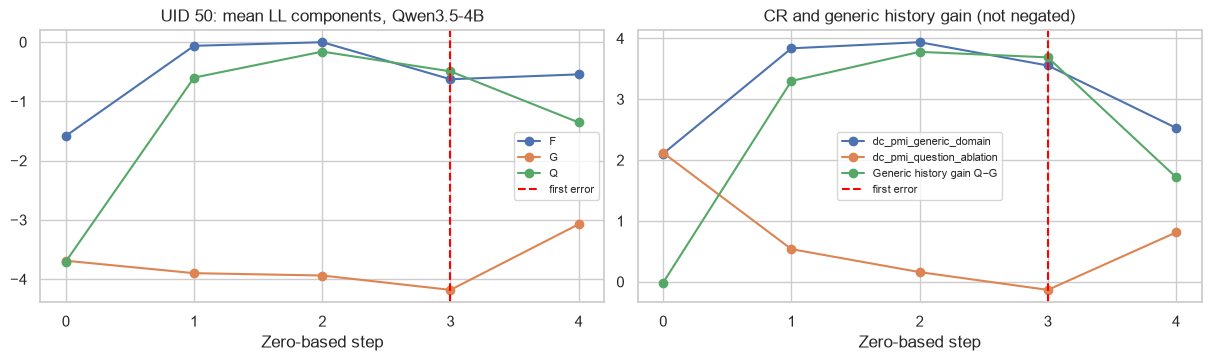

### UID 1: annotated first error = None (zero-based)

Alice, Bob, Claire, Dave, and Eve are playing a game. At the start of the game, they are each holding a ball: Alice has a green ball, Bob has a blue ball, Claire has a yellow ball, Dave has a red ball, and Eve has a brown ball.
As the game progresses, pairs of players trade balls. First, Bob and Claire swap balls. Then, Alice and Dave swap balls. Then, Dave and Claire swap balls. Then, Claire and Bob swap balls. Finally, Bob and Eve swap balls. At the end of the game, Eve has the
Options:
(A) green ball.
(B) blue ball.
(C) yellow ball.
(D) red ball.
(E) brown ball.

Recorded answer: (B); target: (A)

0: A: green, B: blue, C: yellow, D: red, E: brown

1: B: yellow, C: blue, D: red, E: brown

2: A: red, B: yellow, C: blue, D: green, E: brown

3: B: blue, C: yellow, D: red, E: brown

4: B: blue, C: yellow, D: red, E: blue So the answer is (B)


,operation,Alice,Bob,Claire,Dave,Eve
0,initial,green,blue,yellow,red,brown
1,Bob ↔ Claire,green,yellow,blue,red,brown
2,Alice ↔ Dave,red,yellow,blue,green,brown
3,Dave ↔ Claire,red,yellow,green,blue,brown
4,Claire ↔ Bob,red,green,yellow,blue,brown
5,Bob ↔ Eve,red,brown,yellow,blue,green


,step,status,F,G,Q,dc_pmi_generic_domain,dc_pmi_question_ablation
5,0,annotated correct,-0.769,-1.798,-1.791,1.029,1.022
6,1,annotated correct,-0.417,-2.487,-0.510,2.070,0.093
7,2,annotated correct,-0.176,-1.909,-0.279,1.734,0.104
8,3,annotated correct,-0.335,-2.600,-0.335,2.265,0.001
9,4,annotated correct,-0.964,-2.735,-1.370,1.771,0.406


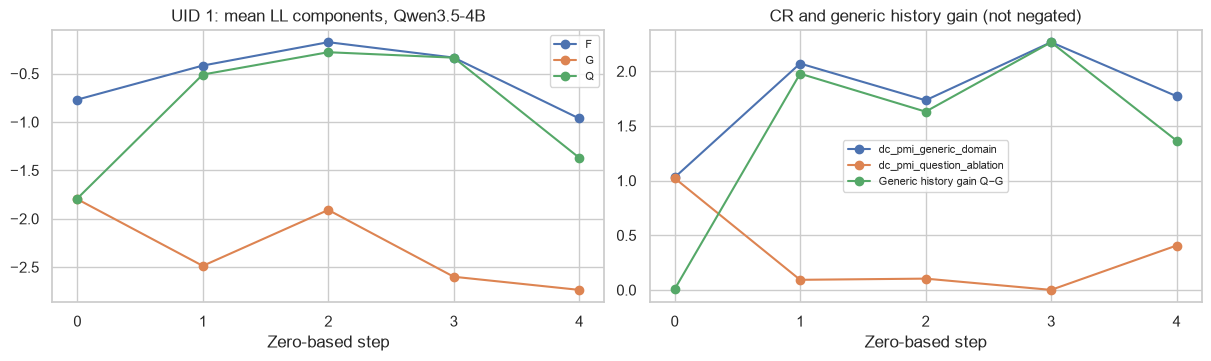

,model,method,original,exclude_8
0,Qwen3.5-4B,−Fully ablated CR,0.358,0.358
1,Qwen3.5-4B,−Question CR,0.904,0.904
2,Qwen3.5-4B,Full surprisal (log perplexity),0.559,0.559
3,Qwen3.5-9B,−Fully ablated CR,0.366,0.365
4,Qwen3.5-9B,−Question CR,0.884,0.883
5,Qwen3.5-9B,Full surprisal (log perplexity),0.546,0.545
6,Qwen3.5-27B,−Fully ablated CR,0.403,0.402
7,Qwen3.5-27B,−Question CR,0.883,0.883
8,Qwen3.5-27B,Full surprisal (log perplexity),0.559,0.559
9,Llama3.1-8B,−Fully ablated CR,0.370,0.366


In [13]:
import re
INITIAL_STATES = {
    '0': {'Alice':'Gatsby','Bob':'Ulysses','Claire':'Moby Dick'},
    '50': {'Alice':'Sam','Bob':'Jamie','Claire':'Melissa'},
    '1': {'Alice':'green','Bob':'blue','Claire':'yellow','Dave':'red','Eve':'brown'},
}

def reference_states(example, initial):
    state = initial.copy()
    rows = [dict(operation='initial', **state)]
    swaps = re.findall(r'(Alice|Bob|Claire|Dave|Eve) and (Alice|Bob|Claire|Dave|Eve) (?:swap|switch)', example.question)
    for a,b in swaps:
        state[a],state[b] = state[b],state[a]
        rows.append(dict(operation=f'{a} ↔ {b}', **state))
    return pd.DataFrame(rows)

for uid, initial in INITIAL_STATES.items():
    e = lookup[uid]
    display(Markdown(f'### UID {uid}: annotated first error = {e.label} (zero-based)'))
    print(e.question)
    print(f'\nRecorded answer: {raw[int(uid)]["answer"]}; target: {e.ground_truth_answer}')
    for i, step in enumerate(e.steps):
        print(f'\n{i}{" <-- annotated first error" if i == e.label else ""}: {step}')
    display(reference_states(e,initial))
    g = one[one.uid.eq(uid)].sort_values('step')
    display(g[['step','status','F','G','Q','dc_pmi_generic_domain','dc_pmi_question_ablation']].round(3))
    fig, axes = plt.subplots(1,2,figsize=(12,3.5),layout='constrained')
    for col in ['F','G','Q']:
        axes[0].plot(g.step,g[col],marker='o',label=col)
    for col in ['dc_pmi_generic_domain','dc_pmi_question_ablation','Generic history gain Q−G']:
        axes[1].plot(g.step,g[col],marker='o',label=col)
    for ax in axes:
        if e.label is not None:
            ax.axvline(e.label,color='red',ls='--',label='first error')
        ax.set(xlabel='Zero-based step',xticks=g.step)
        ax.legend(fontsize=8)
    axes[0].set_title(f'UID {uid}: mean LL components, Qwen3.5-4B')
    axes[1].set_title('CR and generic history gain (not negated)')
    plt.show()

# Sensitivity, not relabeling: remove the eight annotation/answer disagreements.
suspect = set(meta.loc[meta.label.isna() & ~meta.answer_correct,'uid'])
sensitivity = []
for model, g in scores.groupby('model',sort=False):
    for method in ['−Fully ablated CR','−Question CR','Full surprisal (log perplexity)']:
        sensitivity.append(dict(model=model,method=method,original=auc(g,method),
                                exclude_8=auc(g[~g.uid.isin(suspect)],method)))
display(pd.DataFrame(sensitivity).round(3))

## Follow-up 4: practical localization, uncertainty, and failures

A pooled step AUROC is not exact trace accuracy. Here we ask, **given a trace known to contain an error, does its highest-scoring step locate the first error?** All steps remain candidates, including post-error steps. Ties receive fractional credit. This oracle-error-subset metric does not evaluate abstention on correct traces and is not deployment accuracy.

We also bootstrap complete traces (not independent steps) for the original all-step AUROC. The five models evaluate the same traces and are not five independent datasets. Confidence intervals are descriptive; score selection and these diagnostics use the same data, with no held-out validation.

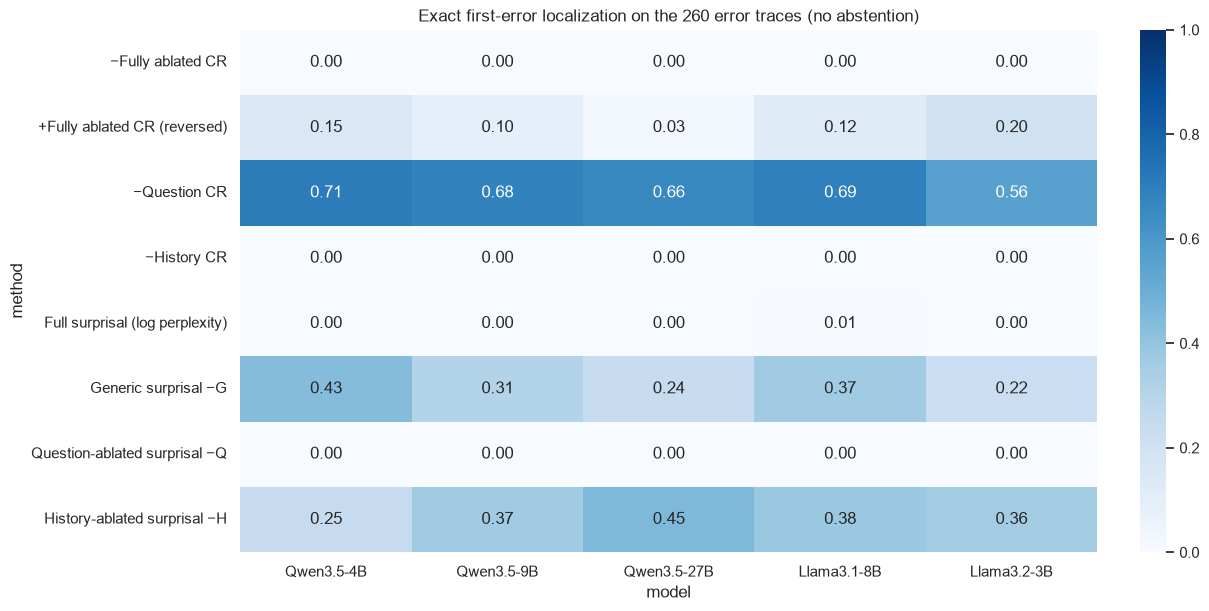

model,Qwen3.5-4B,Qwen3.5-9B,Qwen3.5-27B,Llama3.1-8B,Llama3.2-3B
method,,,,,
−Fully ablated CR,0.004,0.000,0.000,0.004,0.000
+Fully ablated CR (reversed),0.146,0.096,0.031,0.123,0.196
−Question CR,0.708,0.685,0.658,0.692,0.558
−History CR,0.000,0.000,0.000,0.000,0.000
Full surprisal (log perplexity),0.000,0.000,0.004,0.008,0.000
Generic surprisal −G,0.435,0.312,0.238,0.369,0.223
Question-ablated surprisal −Q,0.000,0.000,0.000,0.000,0.000
History-ablated surprisal −H,0.254,0.365,0.450,0.385,0.362


Uniform random-step reference: 0.187


,model,method,auc,lo,hi
0,Qwen3.5-4B,−Fully ablated CR,0.358,0.342,0.377
1,Qwen3.5-4B,−Question CR,0.904,0.885,0.922
2,Qwen3.5-4B,Full surprisal (log perplexity),0.559,0.545,0.573
3,Qwen3.5-9B,−Fully ablated CR,0.366,0.350,0.383
4,Qwen3.5-9B,−Question CR,0.884,0.864,0.903
5,Qwen3.5-9B,Full surprisal (log perplexity),0.546,0.531,0.560
6,Qwen3.5-27B,−Fully ablated CR,0.403,0.388,0.420
7,Qwen3.5-27B,−Question CR,0.883,0.862,0.899
8,Qwen3.5-27B,Full surprisal (log perplexity),0.559,0.545,0.573
9,Llama3.1-8B,−Fully ablated CR,0.370,0.348,0.393


,task,negative_fully_ablated,negative_question
0,dyck_languages,0.583,0.684
1,logical_deduction,0.565,0.416
2,multistep_arithmetic,0.551,0.675
3,tracking_shuffled_objects,0.358,0.904
4,word_sorting,0.592,0.513


### Hard failure for −Question CR: UID 37, margin 0.804

Alice, Bob, Claire, Dave, and Eve are playing a game. At the start of the game, they are each holding a ball: Alice has a brown ball, Bob has a blue ball, Claire has a orange ball, Dave has a pink ball, and Eve has a white ball.
As the game progresses, pairs of players trade balls. First, Dave and Alice swap balls. Then, Alice and Claire swap balls. Then, Claire and Bob swap balls. Then, Eve and Bob swap balls. Finally, Alice and Dave swap balls. At the end of the game, Claire has the
Options:
(A) brown ball.
(B) blue ball.
(C) orange ball.
(D) pink ball.
(E) white ball.

0: A: brown, B: blue, C: orange, D: pink, E: white

1 <-- first error: D: brown, A: pink, C: orange, B: blue, E: white

2: A: pink, C: brown, B: orange, D: blue, E: white

3: A: pink, C: brown, B: white, D: blue, E: orange

4: A: brown, C: pink, B: white, D: blue, E: orange

5: So the answer is (D)


,step,status,−Question CR,−Fully ablated CR,Full surprisal (log perplexity)
205,0,annotated correct,-1.339,-1.351,0.759
206,1,first error,-0.408,-2.472,0.305
207,2,post-error (unknown),0.396,-1.603,0.873
208,3,post-error (unknown),-0.205,-2.418,0.072
209,4,post-error (unknown),-0.078,-2.419,0.166
210,5,post-error (unknown),-0.760,-1.595,1.186


In [14]:
localization = []
for (model, uid), g in scores[scores.label.notna()].groupby(['model','uid'], sort=False):
    for method in METHODS:
        best = g[method].eq(g[method].max())
        localization.append(dict(model=model,uid=uid,method=method,
                                 correct=float((best & g.first_error).sum()/best.sum())))
localization = pd.DataFrame(localization)
localization_table = localization.groupby(['method','model']).correct.mean().unstack().reindex(index=list(METHODS),columns=list(MODELS))
fig, ax = plt.subplots(figsize=(12,6),layout='constrained')
sns.heatmap(localization_table, annot=True,fmt='.2f',vmin=0,vmax=1,cmap='Blues',ax=ax,
            yticklabels=list(METHODS),xticklabels=list(MODELS))
ax.tick_params(axis='y',labelrotation=0)
ax.set_title('Exact first-error localization on the 260 error traces (no abstention)')
plt.show()
display(localization_table.round(3))
print('Uniform random-step reference:', round(np.mean([1/len(e.steps) for e in examples if e.label is not None]),3))

# Cluster-bootstrap original all-step AUROC, preserving every step in each sampled trace.
ci_rows = []
selected_methods = ['−Fully ablated CR','−Question CR','Full surprisal (log perplexity)']
for model, g in scores.groupby('model',sort=False):
    codes, ids = pd.factorize(g.uid)
    rng = np.random.default_rng(2026)
    weights = rng.multinomial(len(ids),np.full(len(ids),1/len(ids)),size=500)
    for method in selected_methods:
        boot = [roc_auc_score(g.first_error,g[method],sample_weight=w[codes]) for w in weights]
        lo,hi = np.quantile(boot,[.025,.975])
        ci_rows.append(dict(model=model,method=method,auc=auc(g,method),lo=lo,hi=hi))
ci = pd.DataFrame(ci_rows)
display(ci.round(3))

# Directly comparable to the source figure, for the small cross-task sample.
cross_auc = pd.DataFrame([dict(task=task,negative_fully_ablated=roc_auc_score(g.first_error,-g.dc_pmi_generic_domain),
    negative_question=roc_auc_score(g.first_error,-g.dc_pmi_question_ablation))
    for task,g in cross.groupby('task')])
display(cross_auc.round(3))

# Deterministic hard case: largest gap between a non-error step and the true first
# error under our strongest pooled detector. This is an intentionally selected failure.
failures = []
for uid,g in one[one.label.notna()].groupby('uid'):
    target_score = g.loc[g.first_error,'−Question CR'].iloc[0]
    failures.append((g['−Question CR'].max()-target_score, int(uid)))
margin, failure_uid = max(failures)
e = lookup[str(failure_uid)]
display(Markdown(f'### Hard failure for −Question CR: UID {e.uid}, margin {margin:.3f}'))
print(e.question)
for i,text in enumerate(e.steps):
    print(f'\n{i}{" <-- first error" if i == e.label else ""}: {text}')
display(one[one.uid.eq(e.uid)][['step','status','−Question CR','−Fully ablated CR','Full surprisal (log perplexity)']].round(3))

## Conclusions

### 1. The pooled reversal is real, but does not mean wrong swaps are better supported

Across all five scorers, negative fully ablated CR has **0.328–0.403 all-step AUROC**, with trace-bootstrap intervals below 0.5. Yet on verified intermediate steps it reaches **0.57–0.65**. At identical trace length and position it is **0.46–0.68**: weak and model-dependent, not consistently reversed. Thus simply flipping its sign would exploit the mixture of step roles rather than reliably detect incorrect transitions.

For Qwen3.5-4B, mean fully ablated CR is **1.81 at correct openings**, **3.50 at correct intermediate steps**, and **3.28 at intermediate first errors**. Within intermediate steps the direction is sensible; pooling in the 300 error-free openings and mostly post-error conclusions changes the ranking. This is a strong *composition/position confound*, not evidence that the model universally prefers incorrect reasoning.

### 2. What makes these traces distinctive?

They repeatedly emit compact, near-identical person–object state lists. Intermediate steps are extraordinarily predictable once the vocabulary, format and previous state are supplied. Without history the generic prompt cannot anticipate those lists, even if their permutation is wrong. The score decomposes as **F−G = (F−Q) + (Q−G)**. At intermediate first errors in Qwen3.5-4B, the mean terms are **3.275 = 0.009 + 3.266**: almost all fully ablated relevance is generic-history gain, not incremental support from the question. At correct intermediate steps, the question contributes **0.319**.

The actual traces make this tangible. In UID 0 the final swap incorrectly changes Bob's book although Bob is not swapping. In UID 50 the final Alice–Claire swap instead changes Alice and Bob. Both still look like familiar, fluent state lists. Their question CR becomes negative while their fully ablated CR remains large. This supports the vocabulary/format/history explanation, but the cache-only analysis does **not** isolate which individual tokens cause it; controlled new counterfactual scoring would be needed for that causal claim.

### 3. Which score should be used?

- **For ranking all steps or locating an error within a trace: negative question-ablated CR.** All-step AUROC is **0.841–0.904**; verified-step AUROC is **0.89–0.93**. Exact first-error localization on the 260 known-error traces is **56–71%**. The denominator preserves the same history, largely cancelling the history-driven advantage of intermediate steps.
- **For comparisons at the same position and length: full-context surprisal / perplexity is excellent.** Conditional AUROC is **0.92–0.99**, and it beats the matched error-free control in **87.5–100%** of the 40 matched pairs. But pooled AUROC is only **0.42–0.56**, and unconstrained within-trace argmax almost never selects the annotated error: openings/conclusions are intrinsically more surprising. Strong matched discrimination is not the same as a usable raw threshold or trace-local detector.
- **Fully ablated and history-ablated CR are poor raw trace-local scores here.** Their role dependence dominates; neither should be recommended solely from a pooled sign flip. No fitted threshold or supervised model was tuned in this investigation.

### 4. Not all the apparent failures are genuine reasoning-detector failures

Eight traces labeled error-free have wrong recorded answers. UID 1 demonstrably violates the swap sequence, despite its null error label. Removing those eight barely changes the overall AUROCs, so they do not explain the reversal.

The automatically selected worst question-CR localization failure, **UID 37**, exposes another likely annotation problem: annotated step 1 correctly swaps Dave's pink ball and Alice's brown ball. Step 2 is visibly incorrect; question CR selects that step instead. This is a failure against the provided annotation, not convincing evidence that the detector missed the first actual error. We do not silently relabel it, and this small manual audit does not establish a dataset-wide noise rate.

### 5. What is and is not unique to this task?

The small Qwen3.5-4B cross-task check reproduces the original contrast: all-step negative fully ablated CR is **0.55–0.59** for the four sampled other BBM tasks, versus **0.36** here. However, excluding post-error steps also reverses logical deduction and word sorting in this sample. History/position confounding is therefore **not exclusive to tracking**; its interaction with compact state-list traces, error locations and the all-step evaluation makes it particularly visible here. Do not infer a universal semantic difference between tracking and all other reasoning domains.

**Limits:** original first-error annotations are noisy; later steps have unknown correctness; matched controls cover only 40/260 error traces; cross-task comparisons use 100 traces/task and one scorer; intervals are descriptive; no out-of-sample detector selection or abstention evaluation. All likelihoods are context-specific **average** token LL, reconstructed denominator means use exact score identities, and all results come from cached runs. Only 300 tracking traces × five models plus 400 comparison traces × one model are loaded per execution.